# Energy demand forecasting: feature engineering & EDA


## Setup & configuration

In [2]:
import warnings
from dataclasses import dataclass, field
from typing import Literal, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
CSV_PATH = r"..\data\processed\singapore\half_hourly.csv"

# Configuration object

In [4]:
@dataclass
class FeatureConfig:
    timestamp_col: str
    target_col: str

    # try to use interval-START so that the first period is 00:00-00:30 everywhere.
    timestamp_label: Literal["start", "end"] = "start"

    tz: Optional[str] = None

    freq: Optional[str] = None

    lags: tuple[str, ...] = ("30min", "1h", "1D", "7D")
    rolling_windows: tuple[str, ...] = ("3h", "1D", "7D")

    country: Optional[str] = None

    min_valid_value: float = 0.0

    cyclical: tuple[str, ...] = ("time_of_day", "day_of_week", "day_of_year")

    extra_drop: tuple[str, ...] = field(default_factory=tuple)

### Transformation: raw frame to regular, interval-start indexed series

- Parse timestamps 
- Handle timezone 
- Force target to numeric and flag non-positive values 
- Sort & remove duplicate 
- Infer sampling interval 
- Transform interval-end stamps to interval-start for parity 
- Form a complete matrix with gaps in lagging and rolling features becoming NaN rows, flagged as `is_imputed_row`.

In [5]:
def read_freq(idx: pd.DatetimeIndex) -> pd.Timedelta:
    
    step = pd.Series(idx).diff().dropna()
    if step.empty:
        raise ValueError("Not enough timestamps to infer frequency.")
    return step.mode().iloc[0]


def read_label(idx: pd.DatetimeIndex, step: pd.Timedelta) -> Optional[str]:
    
    first, last = idx[0], idx[-1]
    first_off = first - first.normalize()
    last_off = last - last.normalize()
    if first_off == step and last_off == pd.Timedelta(0):
        return "end"
    if first_off == pd.Timedelta(0):
        return "start"
    return None

def clean_series(df: pd.DataFrame, cfg: FeatureConfig) -> tuple[pd.DataFrame, dict]:
    """
    Returns a cleaned frame with interval-start timestamps and 
    'is_imputed_row' column to mark rows with NaN data
    Also returns a report describing the data
    """
    for c in (cfg.timestamp_col, cfg.target_col):
        if c not in df.columns:
            raise KeyError(f"Column '{c}' not found. Available: {list(df.columns)}")

    report: dict = {"rows_in": len(df)}
    work = df[[cfg.timestamp_col, cfg.target_col]].copy()

    # timestamps
    ts = pd.to_datetime(work[cfg.timestamp_col], errors="coerce", utc=False)
    
    # normalise via UTC.
    if ts.dtype == object:
        ts = pd.to_datetime(work[cfg.timestamp_col], errors="coerce", utc=True)
    report["unparseable_timestamps"] = int(ts.isna().sum())

    if ts.dt.tz is None:
        if cfg.tz:
            ts = ts.dt.tz_localize(cfg.tz, ambiguous="NaT", nonexistent="NaT")
    elif cfg.tz:
        ts = ts.dt.tz_convert(cfg.tz)

    work.index = pd.DatetimeIndex(ts, name="timestamp")
    work = work.drop(columns=[cfg.timestamp_col])
    work = work[work.index.notna()]

    # target column 
    work[cfg.target_col] = pd.to_numeric(work[cfg.target_col], errors="coerce")
    report["non_numeric_or_null"] = int(work[cfg.target_col].isna().sum())
    bad = work[cfg.target_col] <= cfg.min_valid_value
    report["at_or_below_min_valid"] = int(bad.sum())
    work.loc[bad, cfg.target_col] = np.nan

    # order & remove duplicates 
    if not work.index.is_monotonic_increasing:
        report["was_unsorted"] = True
        work = work.sort_index()
    dups = work.index.duplicated(keep="last")
    report["duplicate_timestamps"] = int(dups.sum())
    work = work[~dups]

    # frequency & interval label 
    step = pd.Timedelta(cfg.freq) if cfg.freq else read_freq(work.index)
    report["freq"] = str(step)

    label = read_label(work.index, step)
    report["label"] = label
    if label and label != cfg.timestamp_label:
        warnings.warn(
            f"Config timestamp_label='{cfg.timestamp_label}'and data dont match")

    if cfg.timestamp_label == "end":
        work.index = work.index - step
    work.index.name = "timestamp"

    # complete grid 
    full = pd.date_range(work.index.min(), work.index.max(), freq=step)
    n_before = len(work)
    work = work.reindex(full)
    work.index.name = "timestamp"
    report["gap_rows_inserted"] = int(len(full) - n_before)
    work["is_imputed_row"] = work[cfg.target_col].isna()
    report["missing_target_rows"] = int(work["is_imputed_row"].sum())
    report["rows_out"] = len(work)
    report["start"], report["end"] = str(work.index[0]), str(work.index[-1])
    report["span_days"] = round((work.index[-1] - work.index[0] + step) / pd.Timedelta("1D"), 2)
    return work, report

### Calendar features

In [6]:
def add_calendar_features(df: pd.DataFrame, cfg: FeatureConfig) -> pd.DataFrame:
    out = df.copy()
    idx = out.index
    out["time_of_day"] = idx.hour + idx.minute / 60.0
    out["hour"] = idx.hour
    out["day_of_week"] = idx.day_of_week                       # Monday=0
    out["is_weekend"] = (idx.day_of_week >= 5).astype(int)
    out["day_of_month"] = idx.day
    out["day_of_year"] = idx.day_of_year
    out["week_of_year"] = idx.isocalendar().week.astype(int).values
    out["month"] = idx.month
    out["quarter"] = idx.quarter
    out["year"] = idx.year

    # cyclical features for distance based regression algorithms
    period = {"time_of_day": 24.0, "day_of_week": 7.0, "day_of_year": 365.25,
              "month": 12.0}
    for col in cfg.cyclical:
        p = period[col]
        out[f"{col}_sin"] = np.sin(2 * np.pi * out[col] / p)
        out[f"{col}_cos"] = np.cos(2 * np.pi * out[col] / p)
    
    return out

### Lag and rolling features

In [7]:
def steps(duration: str, step: pd.Timedelta) -> Optional[int]:

    n = pd.Timedelta(duration) / step
    if n < 1 or n != int(n):
        warnings.warn(f"Skipping '{duration}': not a whole multiple of the {step} sampling interval.", stacklevel=3)
        return None
    return int(n)


def add_lag_features(df: pd.DataFrame, cfg: FeatureConfig) -> pd.DataFrame:

    out = df.copy()
    step = read_freq(out.index)
    y = out[cfg.target_col]
    
    for lag in cfg.lags:
        n = steps(lag, step)
        if n is None:
            continue
        if n >= len(out):
            warnings.warn(f"Skipping lag '{lag}': longer than the {len(out)}-row history.", stacklevel=2)
            continue
        out[f"lag_{lag}"] = y.shift(n)
    return out

def add_rolling_features(df: pd.DataFrame, cfg: FeatureConfig) -> pd.DataFrame:
    
    out = df.copy()
    step = read_freq(out.index)
    y_past = out[cfg.target_col].shift(1)
    
    for w in cfg.rolling_windows:
        n = steps(w, step)
        if n is None:
            continue
        if n >= len(out):
            warnings.warn(f"Skipping rolling window '{w}': longer than the {len(out)}-row history.", stacklevel=2)
            continue
        roll = y_past.rolling(n, min_periods=n)
        out[f"roll_mean_{w}"] = roll.mean()
        out[f"roll_std_{w}"] = roll.std()
        out[f"roll_max_{w}"] = roll.max()
        out[f"roll_min_{w}"] = roll.min()
    
    return out

def build_features(clean: pd.DataFrame, 
                   cfg: FeatureConfig,
                   include_lags: bool = True, 
                   include_rolling: bool = True) -> pd.DataFrame:
    """clean_series() output -> modelling frame. Target column is kept as-is."""
    
    out = add_calendar_features(clean, cfg)
    if include_lags:
        out = add_lag_features(out, cfg)
    if include_rolling:
        out = add_rolling_features(out, cfg)
    return out.drop(columns=list(cfg.extra_drop), errors="ignore")

### Chronological train-test split
To avoid data leakage from a random train-test split the data is split chronologically. 

In [8]:
def chronological_split(df: pd.DataFrame, train_frac: float = 0.7, val_frac: float = 0.15):
    n = len(df)
    i, j = int(n * train_frac), int(n * (train_frac + val_frac))
    return df.iloc[:i], df.iloc[i:j], df.iloc[j:]

# Apply to data

In [9]:
raw = pd.read_csv(CSV_PATH)
print(raw.shape)
raw.head(10)

(69888, 7)


,ts_end_singaporetime,date,period,system_demand_mw,nem_forecast_mw,source_file,file_hash
0,2022-11-07 00:30:00+08:00,2022-11-07,1,5676.678890,5574.5,20221107.xls,44d30eda275459a94b38aa4f32b608dbae35b92fa7d835...
1,2022-11-07 01:00:00+08:00,2022-11-07,2,5556.767025,5462.8,20221107.xls,44d30eda275459a94b38aa4f32b608dbae35b92fa7d835...
2,2022-11-07 01:30:00+08:00,2022-11-07,3,5475.695596,5436.7,20221107.xls,44d30eda275459a94b38aa4f32b608dbae35b92fa7d835...
3,2022-11-07 02:00:00+08:00,2022-11-07,4,5410.115955,5365.2,20221107.xls,44d30eda275459a94b38aa4f32b608dbae35b92fa7d835...
4,2022-11-07 02:30:00+08:00,2022-11-07,5,5358.712663,5296.7,20221107.xls,44d30eda275459a94b38aa4f32b608dbae35b92fa7d835...
5,2022-11-07 03:00:00+08:00,2022-11-07,6,5316.136343,5283.5,20221107.xls,44d30eda275459a94b38aa4f32b608dbae35b92fa7d835...
6,2022-11-07 03:30:00+08:00,2022-11-07,7,5293.564363,5240.0,20221107.xls,44d30eda275459a94b38aa4f32b608dbae35b92fa7d835...
7,2022-11-07 04:00:00+08:00,2022-11-07,8,5270.425313,5207.6,20221107.xls,44d30eda275459a94b38aa4f32b608dbae35b92fa7d835...
8,2022-11-07 04:30:00+08:00,2022-11-07,9,5265.957225,5227.6,20221107.xls,44d30eda275459a94b38aa4f32b608dbae35b92fa7d835...
9,2022-11-07 05:00:00+08:00,2022-11-07,10,5277.711423,5207.1,20221107.xls,44d30eda275459a94b38aa4f32b608dbae35b92fa7d835...


In [10]:
cfg = FeatureConfig(
    timestamp_col="ts_end_singaporetime",
    target_col="system_demand_mw",
    timestamp_label="end",
    country="SG",
)

clean, report = clean_series(raw, cfg)
y = clean[cfg.target_col]
pd.Series(report, name="value").to_frame()

,value
rows_in,69888
unparseable_timestamps,0
non_numeric_or_null,0
at_or_below_min_valid,0
duplicate_timestamps,0
freq,0 days 00:30:00
label,end
gap_rows_inserted,0
missing_target_rows,0
rows_out,69888


In [11]:
feats = build_features(clean, cfg)
print(f"{feats.shape[0]} rows x {feats.shape[1]} columns")
feats.head()

69888 rows x 34 columns


,system_demand_mw,is_imputed_row,time_of_day,hour,day_of_week,is_weekend,day_of_month,day_of_year,week_of_year,month,...,roll_max_3h,roll_min_3h,roll_mean_1D,roll_std_1D,roll_max_1D,roll_min_1D,roll_mean_7D,roll_std_7D,roll_max_7D,roll_min_7D
timestamp,,,,,,,,,,,,,,,,,,,,,
2022-11-07 00:00:00+08:00,5676.678890,False,0.0,0,0,0,7,311,45,11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-11-07 00:30:00+08:00,5556.767025,False,0.5,0,0,0,7,311,45,11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-11-07 01:00:00+08:00,5475.695596,False,1.0,1,0,0,7,311,45,11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-11-07 01:30:00+08:00,5410.115955,False,1.5,1,0,0,7,311,45,11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-11-07 02:00:00+08:00,5358.712663,False,2.0,2,0,0,7,311,45,11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
feats.columns

Index(['system_demand_mw', 'is_imputed_row', 'time_of_day', 'hour',
       'day_of_week', 'is_weekend', 'day_of_month', 'day_of_year',
       'week_of_year', 'month', 'quarter', 'year', 'time_of_day_sin',
       'time_of_day_cos', 'day_of_week_sin', 'day_of_week_cos',
       'day_of_year_sin', 'day_of_year_cos', 'lag_30min', 'lag_1h', 'lag_1D',
       'lag_7D', 'roll_mean_3h', 'roll_std_3h', 'roll_max_3h', 'roll_min_3h',
       'roll_mean_1D', 'roll_std_1D', 'roll_max_1D', 'roll_min_1D',
       'roll_mean_7D', 'roll_std_7D', 'roll_max_7D', 'roll_min_7D'],
      dtype='str')

In [13]:
# These new features introduce some NaN values into the dataframe 
# but the amount of rows affected by NaN values is less than 0.5% of the data
nan_counts = feats.isna().sum()
nan_counts[nan_counts > 0]

lag_30min         1
lag_1h            2
lag_1D           48
lag_7D          336
roll_mean_3h      6
roll_std_3h       6
roll_max_3h       6
roll_min_3h       6
roll_mean_1D     48
roll_std_1D      48
roll_max_1D      48
roll_min_1D      48
roll_mean_7D    336
roll_std_7D     336
roll_max_7D     336
roll_min_7D     336
dtype: int64

# Exploratory data analysis

In [14]:
# Checking the characteristics of energy demand

step = pd.Timedelta(report["freq"])
per_day = int(pd.Timedelta("1D") / step)

print(y.describe().round(3))
print(f"\nskew = {y.skew():.2f}   excess kurtosis = {y.kurt():.2f}")

count    69888.000
mean      6834.594
std        693.643
min       4933.552
25%       6288.152
50%       6871.707
75%       7379.581
max       8619.804
Name: system_demand_mw, dtype: float64

skew = -0.09   excess kurtosis = -0.77


In [15]:
g = y.groupby(y.index.normalize())
daily = y.resample("1D").agg(["mean", "min", "max"])
daily["peak_time"] = g.apply(lambda s: s.idxmax().strftime("%H:%M")).reindex(daily.index)
daily["trough_time"] = g.apply(lambda s: s.idxmin().strftime("%H:%M")).reindex(daily.index)
daily["dow"] = daily.index.day_name().str[:3]

daily.round(0).head(15)

,mean,min,max,peak_time,trough_time,dow
timestamp,,,,,,
2022-11-07 00:00:00+08:00,6455.0,5266.0,7292.0,14:30,04:00,Mon
2022-11-08 00:00:00+08:00,6529.0,5396.0,7340.0,14:30,03:30,Tue
2022-11-09 00:00:00+08:00,6519.0,5432.0,7181.0,11:00,03:30,Wed
2022-11-10 00:00:00+08:00,6522.0,5453.0,7171.0,14:00,03:30,Thu
2022-11-11 00:00:00+08:00,6541.0,5456.0,7223.0,14:00,04:00,Fri
2022-11-12 00:00:00+08:00,6199.0,5463.0,6782.0,11:00,04:00,Sat
2022-11-13 00:00:00+08:00,6013.0,5321.0,6549.0,19:30,04:30,Sun
2022-11-14 00:00:00+08:00,6539.0,5297.0,7296.0,14:30,04:00,Mon
2022-11-15 00:00:00+08:00,6617.0,5460.0,7336.0,14:00,04:00,Tue


In [16]:
print("Most frequent peak time: ", daily["peak_time"].mode()[0])
print("Most frequent trough time: ",daily["trough_time"].mode()[0])

Most frequent peak time:  11:00
Most frequent trough time:  04:00


### Outlier analysis

In [39]:
df_w = feats.assign(wow=feats[cfg.target_col] - feats["lag_7D"]).dropna(subset=["wow"])

# IQR calculated separately for each hour of day
q = df_w.groupby("hour")["wow"].quantile([.25, .75]).unstack()
iqr_h = q[0.75] - q[0.25]
df_w["lo"] = df_w["hour"].map(q[0.25] - 1.5 * iqr_h)
df_w["hi"] = df_w["hour"].map(q[0.75] + 1.5 * iqr_h)
df_w["outlier"] = (df_w["wow"] < df_w["lo"]) | (df_w["wow"] > df_w["hi"])

n_hi = int((df_w["wow"] > df_w["hi"]).sum())
n_lo = int((df_w["wow"] < df_w["lo"]).sum())
print(f"Rows analysed: {len(df_w)}")
print(f"Flagged: {n_hi + n_lo} ({(n_hi + n_lo) / len(df_w) * 100:.2f}%)  "
      f"[{n_hi} unusually high, {n_lo} unusually low]")

Rows analysed: 69552
Flagged: 2549 (3.66%)  [1199 unusually high, 1350 unusually low]


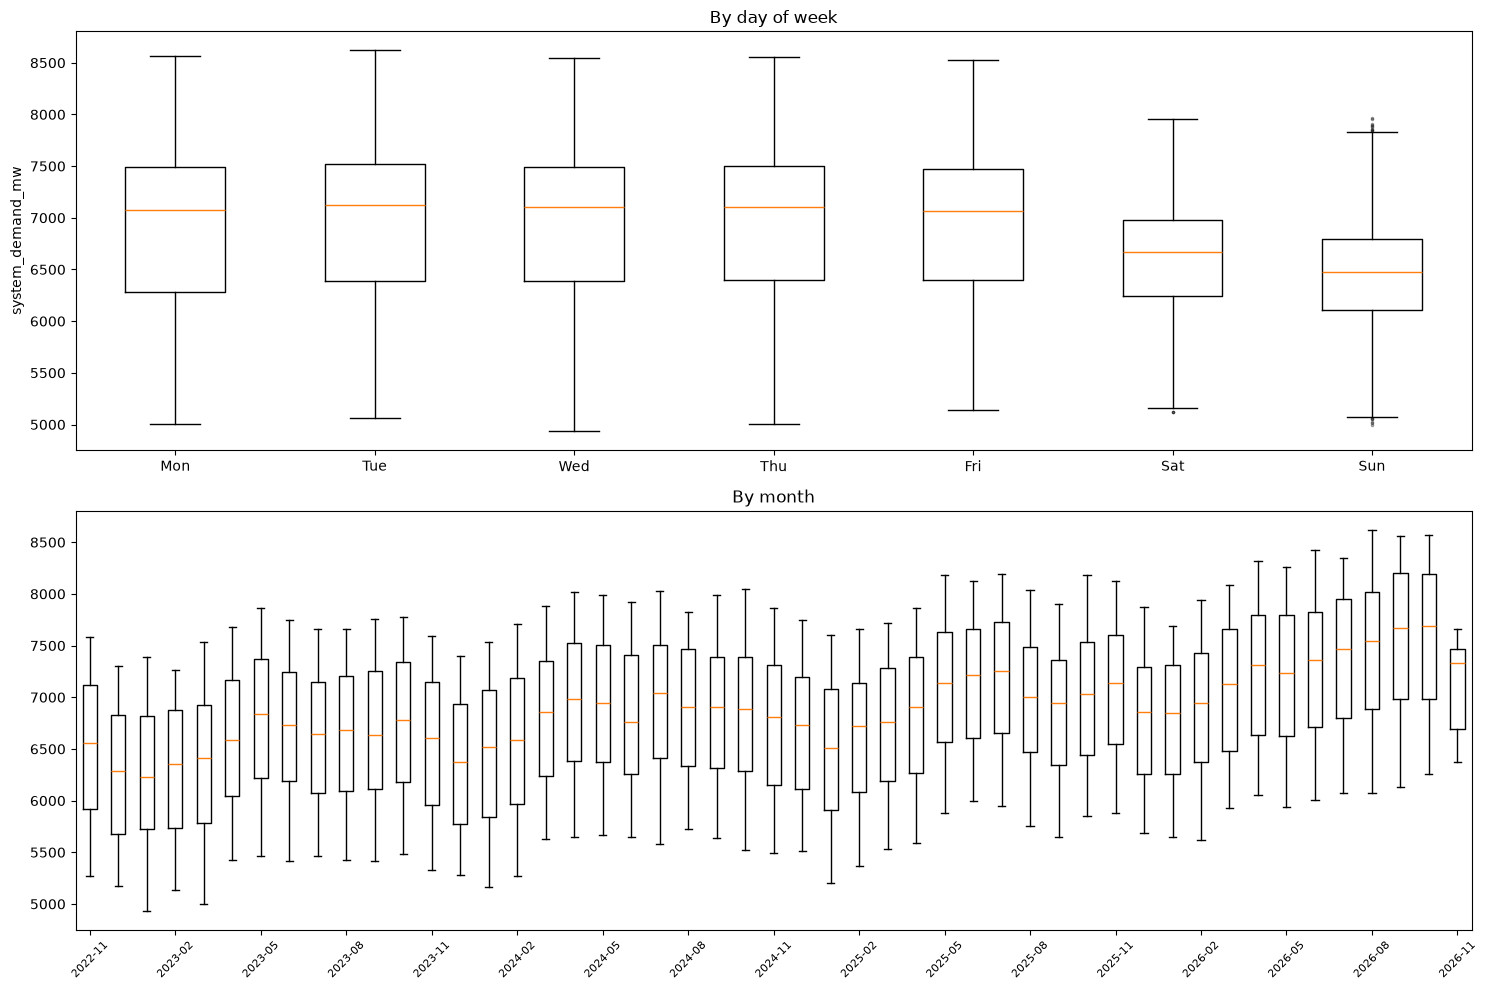

In [38]:
dow_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
months = sorted(y.groupby(y.index.strftime("%Y-%m")).groups)
by_month = y.groupby(y.index.strftime("%Y-%m"))

fig, axs = plt.subplots(2,1 , figsize=(15, 10))

data = [feats.loc[feats["day_of_week"] == d, cfg.target_col].values for d in range(7)]
axs[0].boxplot(data, flierprops=dict(marker=".", markersize=3, alpha=.4))
axs[0].set_xticks(range(1, 8)); axs[0].set_xticklabels(dow_order)
axs[0].set_title("By day of week"); axs[0].set_ylabel(cfg.target_col)

data = [by_month.get_group(m).values for m in months]
axs[1].boxplot(data, flierprops=dict(marker=".", markersize=3, alpha=.4))
step_lbl = 3
axs[1].set_xticks(range(1, len(months) + 1, step_lbl))
axs[1].set_xticklabels(months[::step_lbl], rotation=45, fontsize=8)
axs[1].set_title("By month")
fig.tight_layout()
plt.show()

### Mapping demand over time

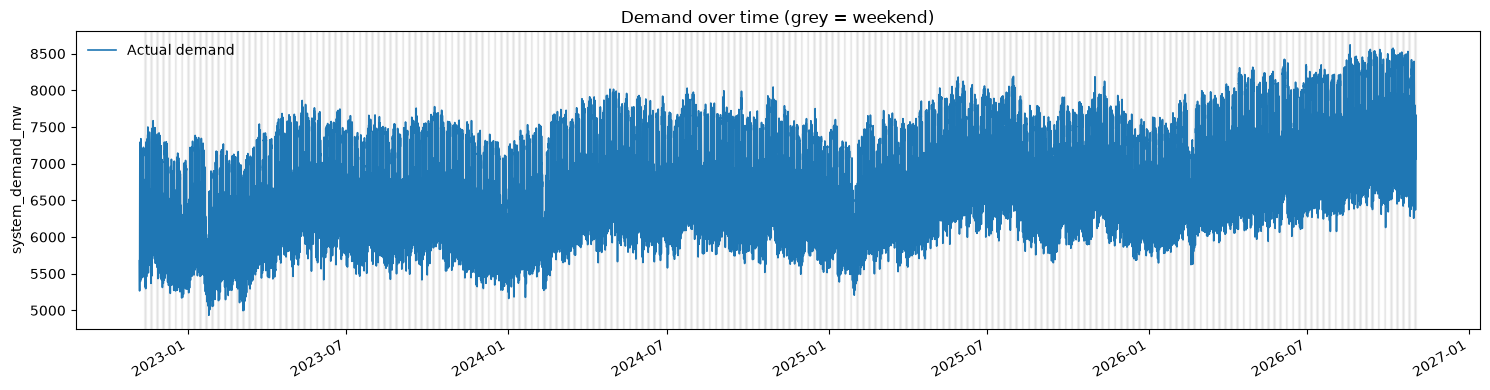

In [17]:
fig, ax = plt.subplots(figsize=(15, 4))
ax.plot(y.index, y.values, lw=1.2, label="Actual demand")


for d in daily.index[daily["dow"].isin(["Sat", "Sun"])]:
    ax.axvspan(d, d + pd.Timedelta("1D"), color="grey", alpha=.08)

h, l = ax.get_legend_handles_labels()

ax.legend(dict(zip(l, h)).values(), dict(zip(l, h)).keys(), loc="upper left", ncol=3, frameon=False)
ax.set_ylabel(cfg.target_col); ax.set_title("Demand over time (grey = weekend)")

fig.autofmt_xdate(); fig.tight_layout(); plt.show()

### Distribution

Text(0.5, 0, 'system_demand_mw')

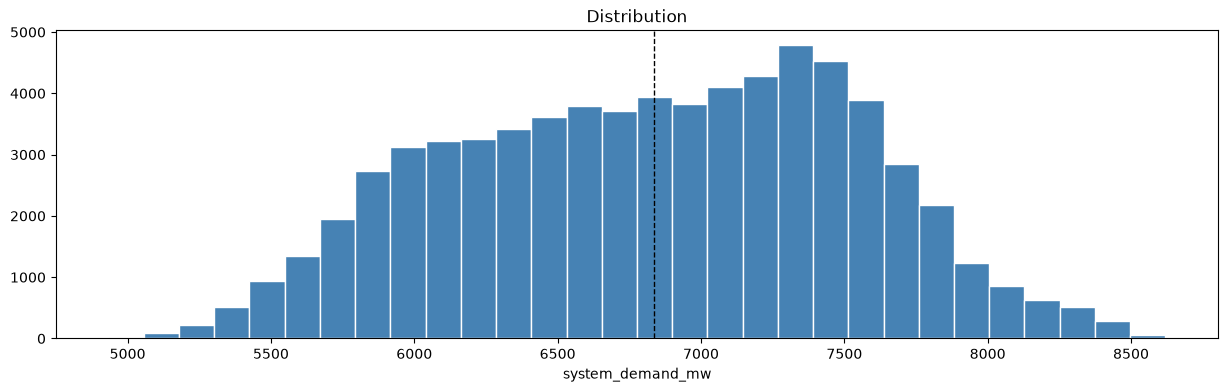

In [18]:
fig, axs = plt.subplots(figsize=(15, 4))
axs.hist(y.dropna(), bins=30, color="steelblue", edgecolor="white")
axs.axvline(y.mean(), color="k", ls="--", lw=1)
axs.set_title("Distribution"); axs.set_xlabel(cfg.target_col)

### Intraday demand by day of week

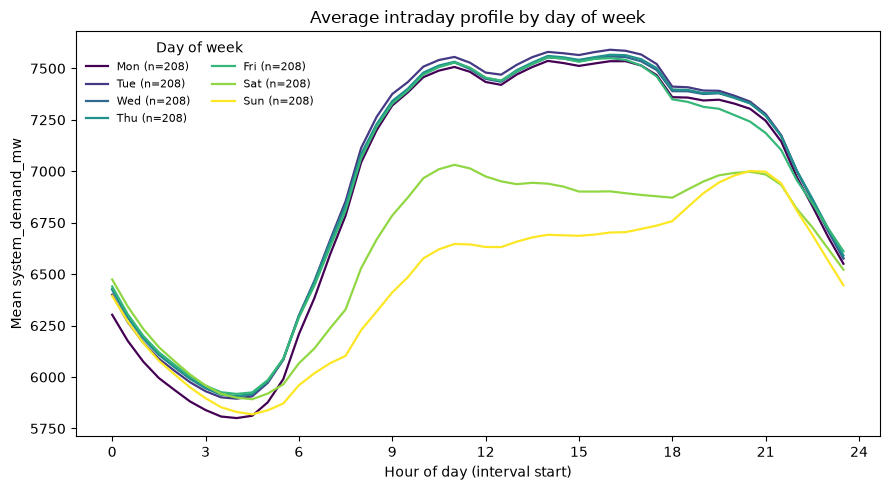

In [19]:
dow_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
cmap = plt.get_cmap("viridis")

prof = (feats.groupby(["day_of_week", "time_of_day"])[cfg.target_col]
           .agg(["mean", "std", "count"])
           .reset_index())

fig, ax = plt.subplots(figsize=(9, 5))
for dow in range(7):
    p = prof[prof["day_of_week"] == dow]
    if p.empty:
        continue

    n_days = feats.index[feats["day_of_week"] == dow].normalize().nunique()
    color = cmap(dow / 6)

    ax.plot(p["time_of_day"], p["mean"], lw=1.6, color=color,
            label=f"{dow_order[dow]} (n={n_days})")

ax.set_xlabel("Hour of day (interval start)")
ax.set_ylabel(f"Mean {cfg.target_col}")
ax.set_xticks(range(0, 25, 3))
ax.legend(ncol=2, fontsize=8, frameon=False, title="Day of week")
ax.set_title("Average intraday profile by day of week")
fig.tight_layout(); plt.show()

### Heatmap: Day x Time of day

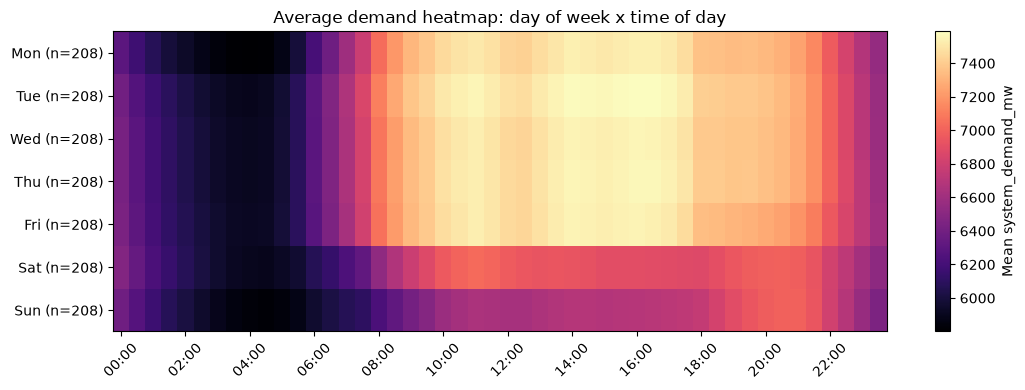

In [20]:
piv = (feats.groupby(["day_of_week", "time_of_day"])[cfg.target_col]
          .mean()
          .unstack("time_of_day")
          .reindex(range(7)))

n_days = {d: feats.index[feats["day_of_week"] == d].normalize().nunique() for d in range(7)}
row_labels = [f"{dow_order[d]} (n={n_days[d]})" for d in range(7)]

col_labels = [f"{int(t):02d}:{int(round((t % 1) * 60)):02d}" for t in piv.columns]
stride = max(piv.shape[1] // 12, 1)

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(piv.values, aspect="auto", cmap="magma")
ax.set_yticks(range(7)); ax.set_yticklabels(row_labels)
ax.set_xticks(range(0, piv.shape[1], stride))
ax.set_xticklabels(col_labels[::stride], rotation=45)
ax.grid(False)
fig.colorbar(im, label=f"Mean {cfg.target_col}")
ax.set_title("Average demand heatmap: day of week x time of day")
fig.tight_layout(); plt.show()

### Autocorrelation

ACF at 1 step = 0.991   at 1 day = 0.885   at 2 days = 0.795


Text(0.5, 0, 'Lag (steps)')

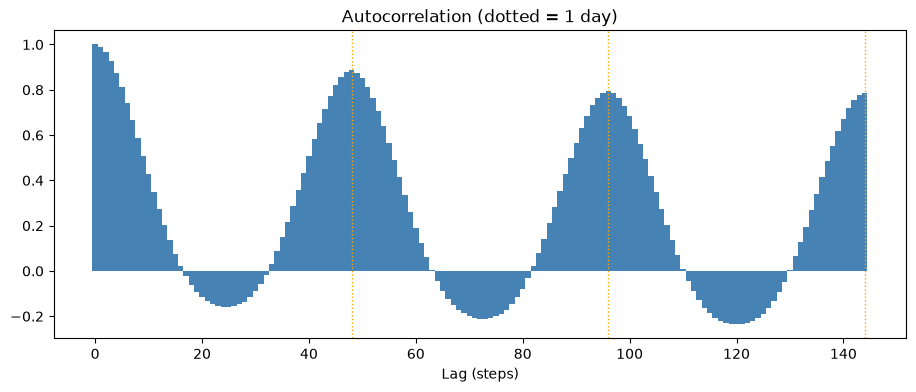

In [21]:
def acf(s, nlags):
    s = s.dropna().values - s.dropna().mean()
    d = (s ** 2).sum()
    return np.array([1.0] + [(s[:-k] * s[k:]).sum() / d for k in range(1, nlags + 1)])

nlags = min(len(y) // 2, per_day * 3)
r = acf(y, nlags)
print(f"ACF at 1 step = {r[1]:.3f}   at 1 day = {r[per_day]:.3f}" +
      (f"   at 2 days = {r[2 * per_day]:.3f}" if nlags >= 2 * per_day else ""))

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(nlags + 1), r, width=1.0, color="steelblue")
for k in range(per_day, nlags + 1, per_day):
    ax.axvline(k, color="orange", ls=":", lw=1)
ax.set_title("Autocorrelation (dotted = 1 day)"); ax.set_xlabel("Lag (steps)")

## Findings & limitations

**Data quality.** 69,888 rows covering Mon 7 Nov 2022 to Sun 1 Nov 2026 at 30-minute resolution, which is exactly 1,456 days or 208 whole weeks (every weekday has n=208). There are no gaps, duplicates, nulls or non-positive values, so no imputation was needed. Timestamps were interval-ending and were shifted to interval-start. The lag and rolling features leave NaNs only in the first 336 rows (0.48% of the data), caused by the 7-day lag and window.

**Findings**

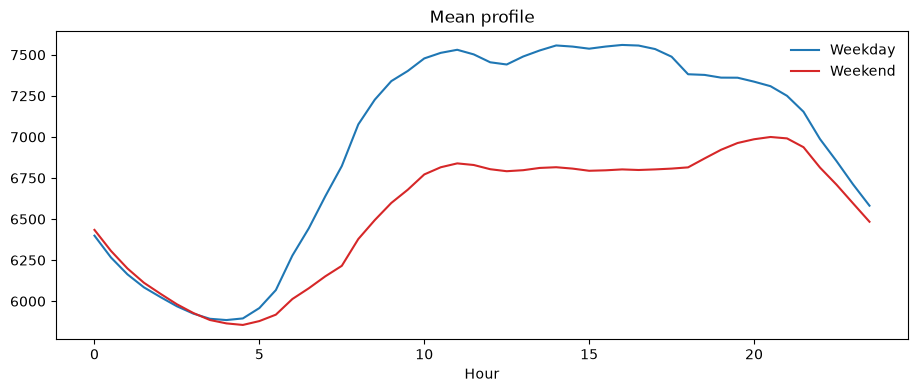

In [24]:
fig, ax = plt.subplots(figsize=(11, 4))
for flag, lab, c in [(0, "Weekday", "tab:blue"), (1, "Weekend", "tab:red")]:
    sub = feats[(feats["is_weekend"] == flag)]
    if len(sub):
        prof = sub.groupby("time_of_day")[cfg.target_col].mean()
        ax.plot(prof.index, prof.values, label=lab, color=c)
ax.set_title("Mean profile")
ax.set_xlabel("Hour")
ax.legend(frameon=False)
plt.show()

- **Weekday and weekend demand follow clearly different patterns.** This is the strongest structure in the data (intraday plot and heatmap).
  - During weekdays demand climbs from around 5,900 MW around 04:00 to a daytime plateau of around 7,500 MW, then falls from about 18:00 to  about 6400 MW by midnight.
  - Weekends have a much lower plateau. Daytime demand is roughly 500 MW lower on Saturday (~7,000 MW) and about 850 MW lower on Sunday (~6,650 MW) than on a weekday.
  - Weekend demand rises into an evening peak so the gap to weekdays is narrowest in the evening and nearly closes after 22:00.
  - All days converge at the overnight trough, so the weekday/weekend difference is almost entirely a daytime effect.
- **Monday is distinct from Tue–Fri.** Its overnight and early-morning demand is lower (it inherits Sunday's low base), and its morning ramp starts a little later. 
- **Strong daily cycle.** The most frequent trough time is 04:00. The most frequent peak time is 11:00, but this should not be over-read: the weekday plateau is flat to within ~100 MW from late morning to ~17:30, so the exact peak time on a weekday is unstable, and Saturday peaks at about 11:00.
- **Upward trend over the years.** Both the baseline and the peaks drift upward over the four years: peaks go from ~7,300–7,500 MW in late 2022 to ~8,500 MW by mid-to-late 2026 (read from the time-series plot). The series is not stationary.
- **Seasonality.** Demand appears lower around the turn of each year and higher in the middle of the year, with sharp short dips around January–February. Causes can be cultural or geographical.
- **Overall distribution.** Mean 6,835 MW, std 694 MW, range 4,934–8,620 MW. It is nearly symmetric (skew −0.09) and moderately platykurtic (excess kurtosis −0.77), with a peak near 7,300–7,400 MW. This is a mixture of day/night, weekday/weekend and trend effects and outliers are scarce at hourly granularity(<4%) but even less noticeable during macro (weekly/monthly) analysis.
- **Autocorrelation.** 0.991 at one step (30 min), 0.885 at one day and 0.795 at two days. The ACF oscillates with a 24-hour period, dipping to about −0.15 to −0.2 at half-day lags, which confirms strong daily cylcicality. 

**Limitations**

1. **Outside causes of demand are not captured.** Temperature, humidity and other weather variables are not included, which likely explains part of the variation in yearly patterns.
2. **The data is too small for effective tesing** Due to the possibility of data leakage and chronological split the test set only spans from 28 Mar–1 Nov 2026. The test set therefore covers only about seven months, no full yearly cycle, and demand also steadily rises towards the end of the data. 
3. **Only about four yearly cycles.** The yearly pattern is hard to separate from the trend, and `day_of_year` features will be noisy.